In [1]:
from utils.binaries import *
from utils.plotting import *
from matplotlib.colors import CenteredNorm
from scipy.optimize import brentq
from scipy.stats import zscore

# from pathlib import Path
# from itertools import pairwise

# set_plt_style("double")

# import xml.etree.ElementTree as ET

# # inGrid 0=off-grid, 1=SD-1500, 2=SD-750, 3=SD-433

# station_list = ET.parse('/home/filip/Public/offline/install/d0e2917c5/install/share/auger-offline/config/SStationList.xml').getroot().findall("station")
# all_northing, all_easting, all_altitude = [], [], []
# sd1500, sd750, sd433 = [], [], []

# for station in station_list:
#     if (_id := int(station.get('id'))) <= 100: continue

#     all_northing.append(float(station.find('northing').text.strip()) / 1000)
#     all_easting.append(float(station.find('easting').text.strip()) / 1000)
#     # all_altitude.append(float(station.find('altitude').text.strip()) / 1000)

#     grids = station.find('inGrid').text.strip()

#     # if '1' in grids: sd1500.append(_id)
#     # if '2' in grids: sd750.append(_id)
#     # if '3' in grids: sd433.append(_id)

# # all_altitude = np.array(all_altitude)


21:21:26 (   +2.0s) [INFO   ] -- import logging
21:21:27 (  +812ms) [INFO   ] -- import numpy as np
21:21:27 (   +14ms) [INFO   ] -- import uncertainties
21:21:29 (   +1.3s) [INFO   ] -- import pandas as pd
21:21:29 (    +1ms) [WARNING] -- pandas support to be dropped at some point!
21:21:29 (    +1ms) [INFO   ] -- import binaries.tools as tools
21:21:29 (    +2ms) [INFO   ] -- set MONI_PATH = PosixPath('/home/filip/Data/monit_and_sd')
21:21:29 (    +0ms) [INFO   ] -- set HIST_PATH = PosixPath('/home/filip/Data/monit_and_sd')
21:21:29 (    +1ms) [INFO   ] -- set PLOT_PATH = PosixPath('/home/filip/Data/plots')
21:21:29 (    +0ms) [INFO   ] -- set DATA_PATH = PosixPath('/home/filip/Data')
21:21:29 (    +0ms) [INFO   ] -- set SCAN_PATH = PosixPath('/home/filip/Public/xy-calibration')
21:21:29 (    +1ms) [INFO   ] -- set OFLN_PATH = PosixPath('/home/filip/Public/offline/install')
21:21:29 (  +422ms) [INFO   ] -- import matplotlib.pyplot as plt
21:21:31 (   +1.9s) [INFO   ] -- import seabor

In [2]:
file = "/media/filip/Drive/ssd_online_calib/combined/prod_all.out"

data = tools.pickle_load(file)

In [3]:
info = []

for _, df_station in data.groupby("StationId"):

    info.append([
        *df_station.iloc[0, 2:5].values,
        ratio := np.sum(df_station['SSDRate'].between(65, 75)) / len(df_station),
        ratio > 0.1
    ])

stations = pd.DataFrame(info, columns=['id', 'x', 'y', 'uptime_fraction', 'has_ssd'])

# drop one doublet station for visualization
stations.drop(stations[stations['id'] == 139].index, axis=0)


,id,x,y,uptime_fraction,has_ssd
0,2,452126.69,6112627.75,0.999281,True
1,5,452130.04,6115232.39,0.999263,True
2,6,452873.72,6113937.00,0.631336,True
3,7,450627.45,6112626.77,0.999245,True
4,11,450997.78,6114128.70,0.999614,True
...,...,...,...,...,...
1610,1893,480535.31,6128265.83,1.000000,True
1611,1899,463374.46,6116540.43,0.998791,True
1612,1902,465624.83,6117820.74,0.999040,True
1613,1904,486624.71,6125620.89,1.000000,True


11:56:29 (  +29.4s) [DEBUG  ] -- font size set to 9.5
11:56:29 (    +2ms) [DEBUG  ] -- label size set to 13.0
11:56:29 (    +1ms) [DEBUG  ] -- figure size set to [3.3, 2.5]
11:56:29 (    +2ms) [DEBUG  ] -- markersize set to 2.0
11:56:29 (    +2ms) [DEBUG  ] -- usetex set to False


Text(0.5, 0, 'Easting / km')

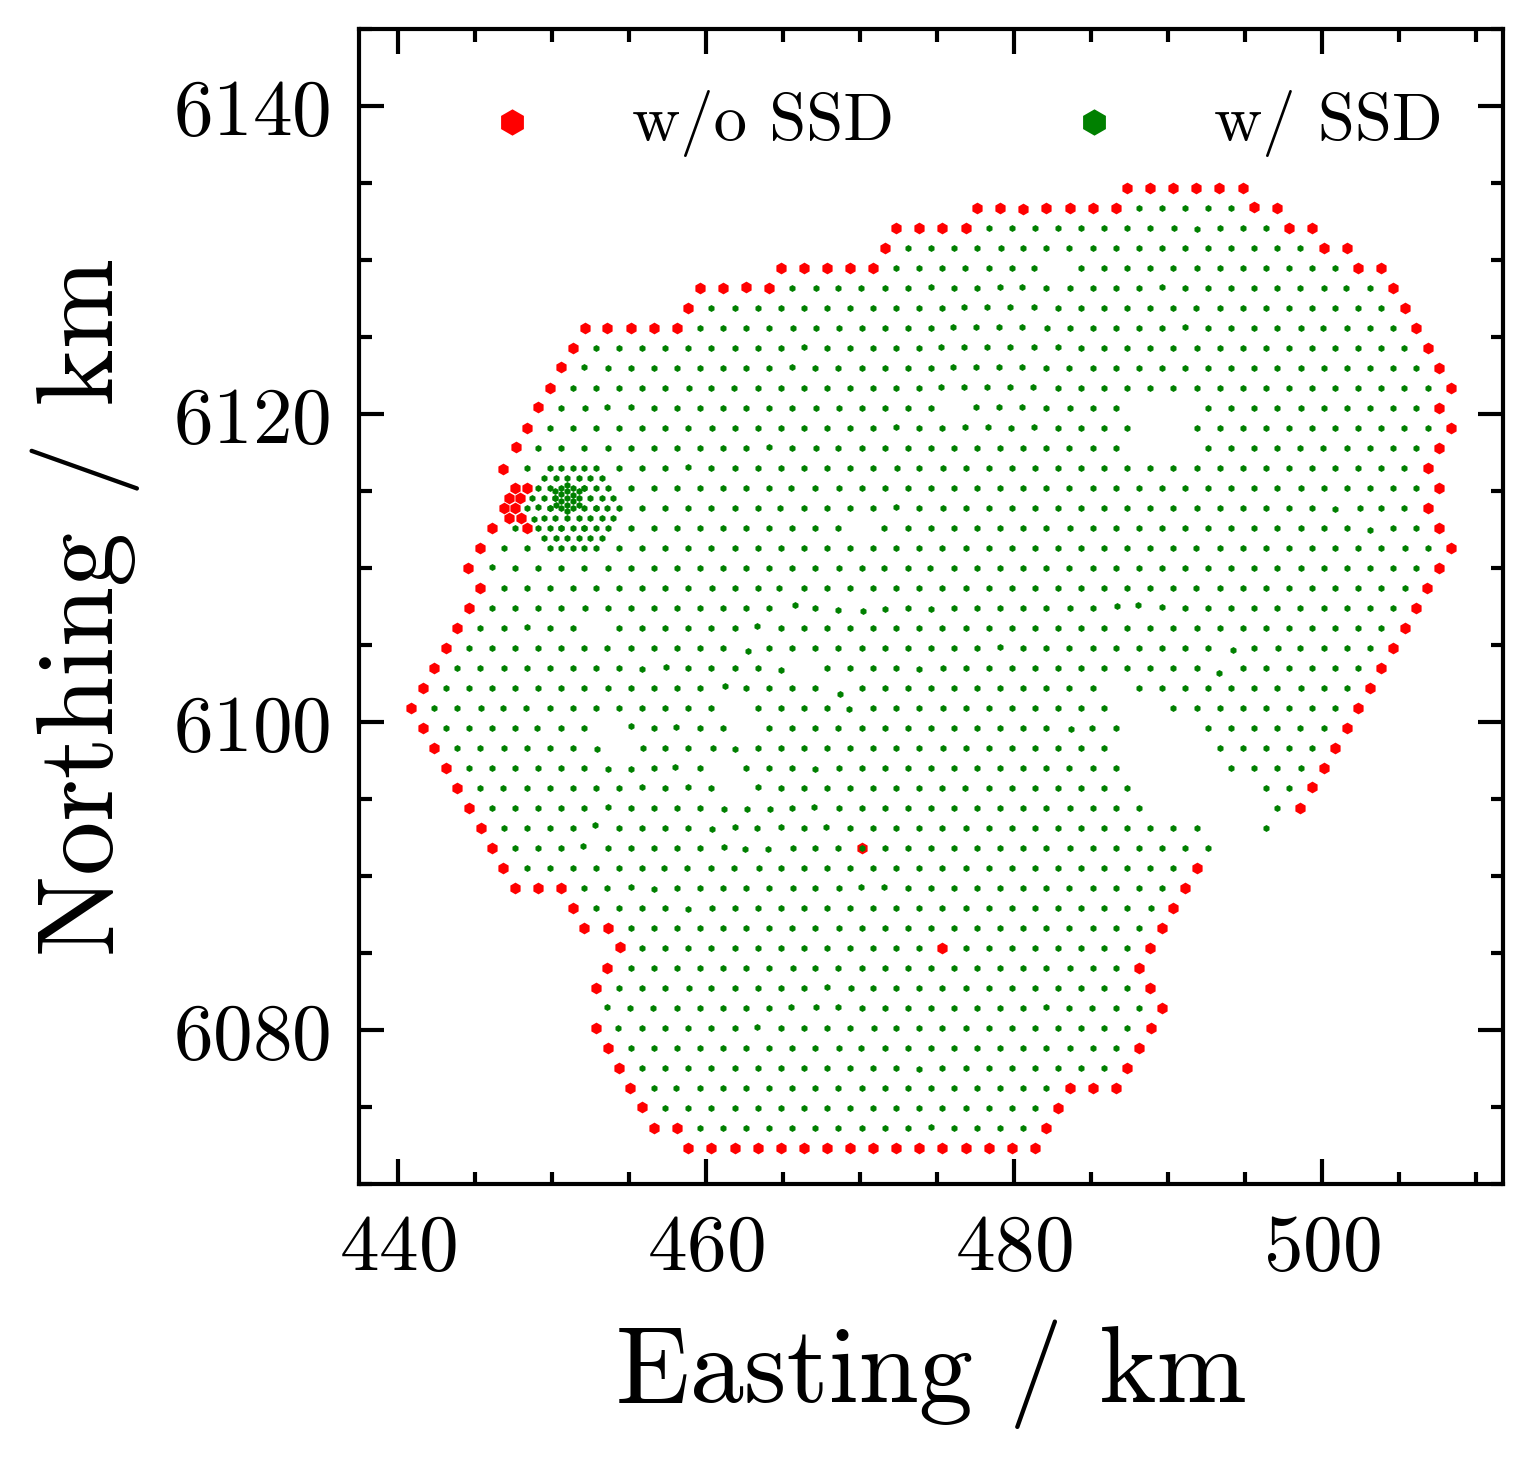

In [4]:
set_plt_style("double")

plt.scatter(stations.loc[stations['has_ssd'] == False, 'x'] / 1e3, stations.loc[stations['has_ssd'] == False, 'y'] /1e3, c = 'r', marker='h', lw=0, s=2)
plt.scatter(stations.loc[stations['has_ssd'] == True, 'x'] / 1e3, stations.loc[stations['has_ssd'] == True, 'y'] /1e3, c = 'g', marker='h', lw=0, s=0.7)

plt.scatter([], [], c = 'r', marker='h', lw=0, s=10, label='w/o SSD')
plt.scatter([], [], c = 'g', marker='h', lw=0, s=10, label='w/ SSD')

plt.legend(ncol=2, fontsize=8)
plt.ylim(6070, 6145)
plt.gca().set_aspect('equal')
plt.ylabel("Northing / km")
plt.xlabel("Easting / km")

In [5]:
stations[(stations['has_ssd'] == False)
         & (stations['x'].between(465000, 480000))
         & (stations['y'].between(6085000, 6095000))]

,id,x,y,uptime_fraction,has_ssd
54,139,470130.35,6091848.95,0.001271,False
144,231,475376.69,6085347.71,0.000000,False


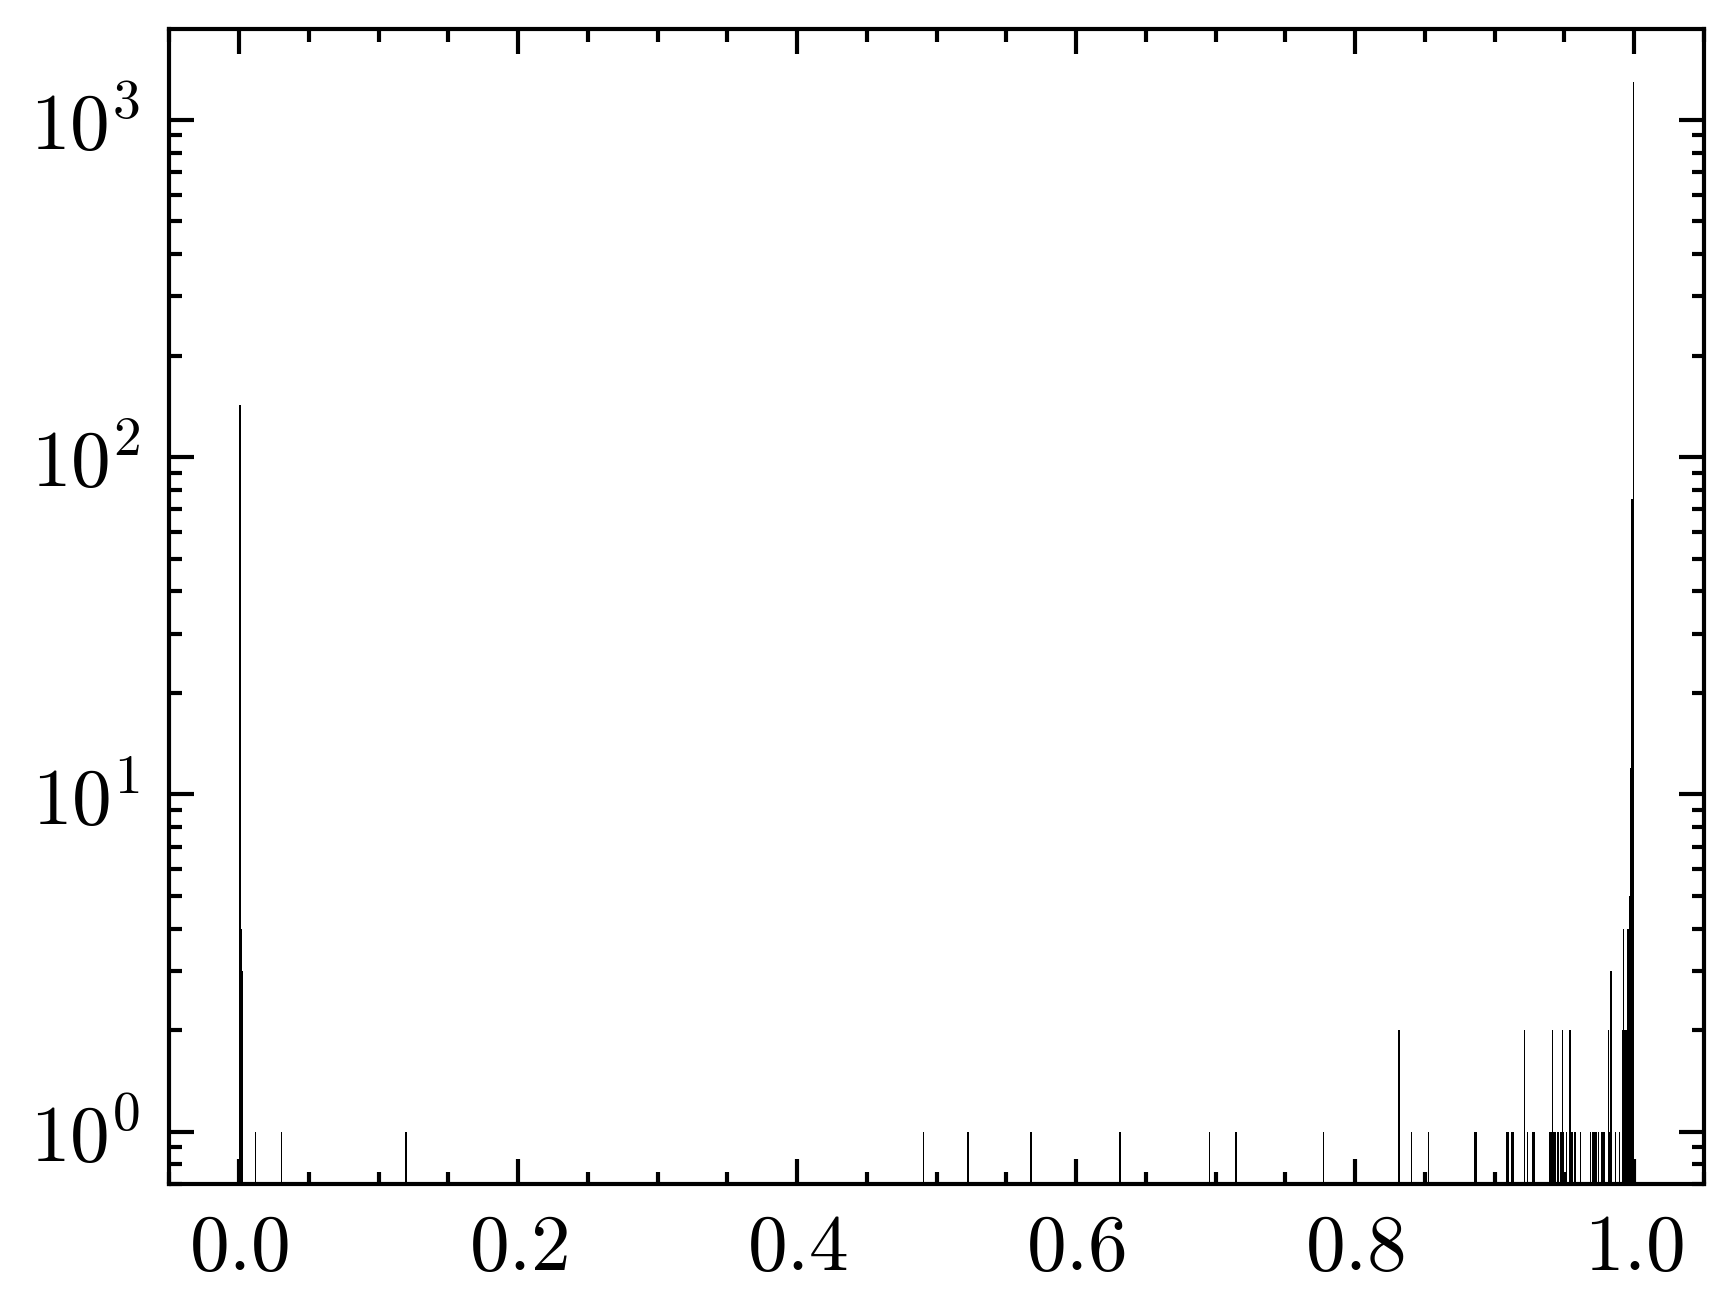

In [6]:
_ = plt.hist(stations['uptime_fraction'], bins=1000)
plt.yscale("log")